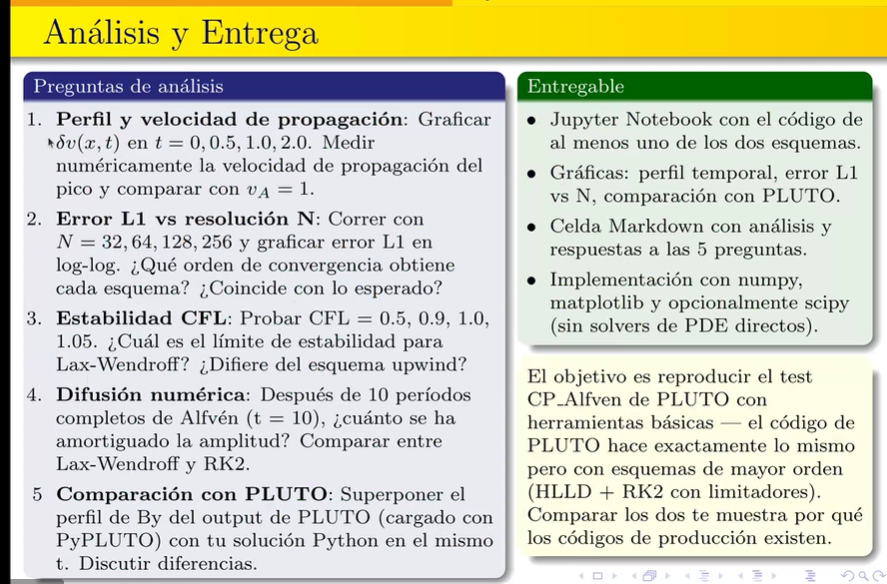

Parámetros y malla

In [1]:
import numpy as np
import matplotlib.pyplot as plt

B0 = 1.0
rho0 = 1.0
mu0 = 1.0
vA = B0/np.sqrt(mu0*rho0)
A = 0.1
L = 1.0

N = 256
CFL = 0.8
dx = L/N
dt = CFL*dx/vA

x = np.linspace(0.5*dx, L - 0.5*dx, N)
dv0 = A*np.sin(2*np.pi*x/L)
dB0 = A*np.sin(2*np.pi*x/L)

print(f'vA = {vA}')
print(f'dx = {dx:.6f}')
print(f'dt = {dt:.6f}')
print(f'pasos por periodo = {L/vA/dt:.1f}')

vA = 1.0
dx = 0.003906
dt = 0.003125
pasos por periodo = 320.0


## Pregunta 1

In [2]:
t_salida = [0.5, 1.0, 2.0]

dv = dv0.copy()
dB = dB0.copy()
t = 0.0

historial_t = [0.0]
historial_dv = [dv.copy()]
perfiles = [dv.copy()]
tiempos_perfil = [0.0]

for k in range(len(t_salida)):
    n_pasos = int(np.ceil((t_salida[k] - t)/dt - 1e-9))
    dt_paso = (t_salida[k] - t)/n_pasos
    for n in range(n_pasos):
        dv_half = 0.5*(dv + np.roll(dv, -1)) + (dt_paso/(2*dx))*(B0/mu0/rho0)*(np.roll(dB, -1) - dB)
        dB_half = 0.5*(dB + np.roll(dB, -1)) + (dt_paso/(2*dx))*B0*(np.roll(dv, -1) - dv)
        dv = dv + (dt_paso/dx)*(B0/mu0/rho0)*(dB_half - np.roll(dB_half, 1))
        dB = dB + (dt_paso/dx)*B0*(dv_half - np.roll(dv_half, 1))
        t = t + dt_paso
        historial_t.append(t)
        historial_dv.append(dv.copy())
    t = t_salida[k]
    perfiles.append(dv.copy())
    tiempos_perfil.append(t)

print(f'pasos totales = {len(historial_t) - 1}')

pasos totales = 640


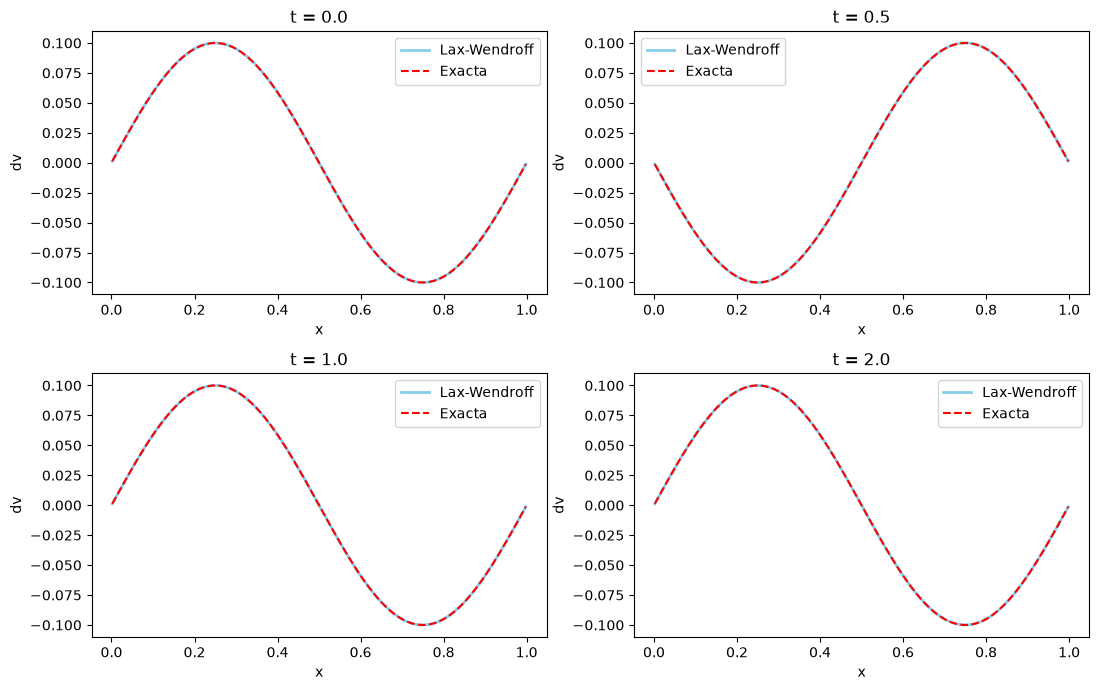

In [3]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for k in range(4):
    fila = k // 2
    columna = k % 2
    dv_exacta = A*np.sin(2*np.pi*(x + vA*tiempos_perfil[k])/L)
    ejes[fila, columna].plot(x, perfiles[k], color='skyblue', lw=2, label='Lax-Wendroff')
    ejes[fila, columna].plot(x, dv_exacta, '--', color='red', label='Exacta')
    ejes[fila, columna].set_title(f't = {tiempos_perfil[k]}')
    ejes[fila, columna].set_xlabel('x')
    ejes[fila, columna].set_ylabel('dv')
    ejes[fila, columna].legend()
plt.tight_layout()
plt.show()

Posición del pico en cada paso

In [4]:
x_pico = []
for n in range(len(historial_dv)):
    perfil = historial_dv[n]
    i_max = np.argmax(perfil)
    y_izq = perfil[i_max - 1]
    y_cen = perfil[i_max]
    y_der = perfil[(i_max + 1) % N]
    desplazamiento = 0.5*(y_izq - y_der)/(y_izq - 2*y_cen + y_der)
    x_pico.append(x[i_max] + desplazamiento*dx)

x_desenrollado = [x_pico[0]]
for n in range(1, len(x_pico)):
    dif = x_pico[n] - x_pico[n - 1]
    dif = dif - L*round(dif/L)
    x_desenrollado.append(x_desenrollado[n - 1] + dif)

print('t      x_pico numérico   x_pico exacto')
for k in range(4):
    n_k = np.argmin(np.abs(np.array(historial_t) - tiempos_perfil[k]))
    x_exacto = (L/4 - vA*tiempos_perfil[k]) % L
    print(f'{tiempos_perfil[k]:.1f}    {x_pico[n_k]:.6f}          {x_exacto:.6f}')

t      x_pico numérico   x_pico exacto
0.0    0.250000          0.250000
0.5    0.750018          0.750000
1.0    0.250036          0.250000
2.0    0.250072          0.250000


Velocidad del pico

In [5]:
t_arr = np.array(historial_t)
y_arr = np.array(x_desenrollado)
n_datos = len(t_arr)

S_t = np.sum(t_arr)
S_tt = np.sum(t_arr*t_arr)
S_y = np.sum(y_arr)
S_ty = np.sum(t_arr*y_arr)

M = np.array([[n_datos, S_t, S_y],
              [S_t, S_tt, S_ty]], dtype=float)

intercambio = False
if abs(M[1, 0]) > abs(M[0, 0]):
    fila_temp = M[0, :].copy()
    M[0, :] = M[1, :]
    M[1, :] = fila_temp
    intercambio = True

factor = M[1, 0]/M[0, 0]
M[1, :] = M[1, :] - factor*M[0, :]

pendiente = M[1, 2]/M[1, 1]
intercepto = (M[0, 2] - M[0, 1]*pendiente)/M[0, 0]

v_numerica = abs(pendiente)
error_relativo = abs(v_numerica - vA)/vA

if pendiente < 0:
    sentido = 'hacia -x'
else:
    sentido = 'hacia +x'

print(f'se intercambiaron filas: {intercambio}')
print(f'pendiente = {pendiente:.6f}  ({sentido})')
print(f'velocidad numérica del pico = {v_numerica:.6f}')
print(f'velocidad de Alfvén         = {vA:.6f}')
print(f'error relativo              = {error_relativo:.2e}')

se intercambiaron filas: True
pendiente = -0.999964  (hacia -x)
velocidad numérica del pico = 0.999964
velocidad de Alfvén         = 1.000000
error relativo              = 3.61e-05


## Pregunta 2


In [6]:
lista_N = [32, 64, 128, 256]
t_fin = 1.0
CFL = 0.8
error_L1 = []

for N in lista_N:
    dx = L/N
    dt = CFL*dx/vA
    x = np.linspace(0.5*dx, L - 0.5*dx, N)
    dv = A*np.sin(2*np.pi*x/L)
    dB = A*np.sin(2*np.pi*x/L)
    n_pasos = int(np.ceil(t_fin/dt - 1e-9))
    dt_paso = t_fin/n_pasos
    for n in range(n_pasos):
        dv_half = 0.5*(dv + np.roll(dv, -1)) + (dt_paso/(2*dx))*(B0/mu0/rho0)*(np.roll(dB, -1) - dB)
        dB_half = 0.5*(dB + np.roll(dB, -1)) + (dt_paso/(2*dx))*B0*(np.roll(dv, -1) - dv)
        dv = dv + (dt_paso/dx)*(B0/mu0/rho0)*(dB_half - np.roll(dB_half, 1))
        dB = dB + (dt_paso/dx)*B0*(dv_half - np.roll(dv_half, 1))
    dv_exacta = A*np.sin(2*np.pi*(x + vA*t_fin)/L)
    error_L1.append(np.mean(np.abs(dv - dv_exacta)))

print('N      error L1      orden p entre resoluciones')
for i in range(len(lista_N)):
    if i == 0:
        print(f'{lista_N[i]:4d}   {error_L1[i]:.3e}     -')
    else:
        p = np.log2(error_L1[i - 1]/error_L1[i])
        print(f'{lista_N[i]:4d}   {error_L1[i]:.3e}     {p:.3f}')

N      error L1      orden p entre resoluciones
  32   9.214e-04     -
  64   2.311e-04     1.995
 128   5.782e-05     1.999
 256   1.446e-05     2.000


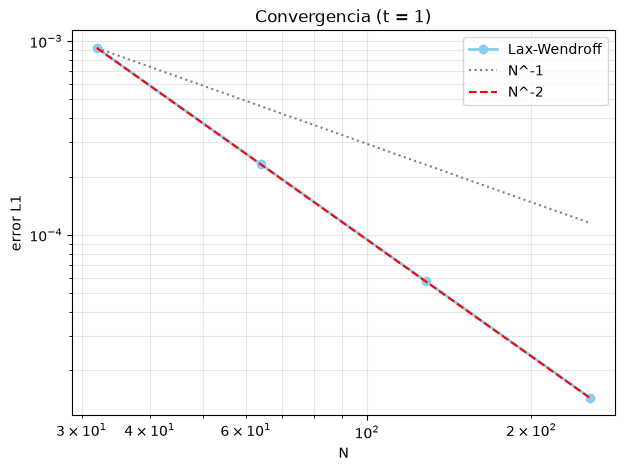

In [7]:
N_arr = np.array(lista_N, dtype=float)
E_arr = np.array(error_L1)

plt.figure(figsize=(7, 5))
plt.loglog(N_arr, E_arr, 'o-', color='skyblue', lw=2, label='Lax-Wendroff')
plt.loglog(N_arr, E_arr[0]*(N_arr/N_arr[0])**(-1), ':', color='gray', label='N^-1')
plt.loglog(N_arr, E_arr[0]*(N_arr/N_arr[0])**(-2), '--', color='red', label='N^-2')
plt.xlabel('N')
plt.ylabel('error L1')
plt.title('Convergencia (t = 1)')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

In [8]:
X = np.log(N_arr)
Y = np.log(E_arr)
n_datos = len(X)

S_x = np.sum(X)
S_xx = np.sum(X*X)
S_y = np.sum(Y)
S_xy = np.sum(X*Y)

M = np.array([[n_datos, S_x, S_y],
              [S_x, S_xx, S_xy]], dtype=float)

intercambio = False
if abs(M[1, 0]) > abs(M[0, 0]):
    fila_temp = M[0, :].copy()
    M[0, :] = M[1, :]
    M[1, :] = fila_temp
    intercambio = True

factor = M[1, 0]/M[0, 0]
M[1, :] = M[1, :] - factor*M[0, :]

pendiente = M[1, 2]/M[1, 1]
intercepto = (M[0, 2] - M[0, 1]*pendiente)/M[0, 0]

print(f'se intercambiaron filas: {intercambio}')
print(f'pendiente = {pendiente:.4f}')
print(f'orden de convergencia p = {-pendiente:.4f}')

se intercambiaron filas: True
pendiente = -1.9981
orden de convergencia p = 1.9981


## Pregunta 3

In [9]:
lista_CFL = [0.5, 0.9, 1.0, 1.05]
t_fin = 2.0
N = 256
dx = L/N
x = np.linspace(0.5*dx, L - 0.5*dx, N)

series_t = []
series_max = []
max_final = []
error_final = []

for CFL in lista_CFL:
    dt = CFL*dx/vA
    dv = A*np.sin(2*np.pi*x/L)
    dB = A*np.sin(2*np.pi*x/L)
    n_pasos = int(np.ceil(t_fin/dt - 1e-9))
    dt_paso = t_fin/n_pasos
    t_serie = [0.0]
    max_serie = [np.max(np.abs(dv))]
    for n in range(n_pasos):
        dv_half = 0.5*(dv + np.roll(dv, -1)) + (dt_paso/(2*dx))*(B0/mu0/rho0)*(np.roll(dB, -1) - dB)
        dB_half = 0.5*(dB + np.roll(dB, -1)) + (dt_paso/(2*dx))*B0*(np.roll(dv, -1) - dv)
        dv = dv + (dt_paso/dx)*(B0/mu0/rho0)*(dB_half - np.roll(dB_half, 1))
        dB = dB + (dt_paso/dx)*B0*(dv_half - np.roll(dv_half, 1))
        t_serie.append((n + 1)*dt_paso)
        max_serie.append(np.max(np.abs(dv)))
    dv_exacta = A*np.sin(2*np.pi*(x + vA*t_fin)/L)
    series_t.append(t_serie)
    series_max.append(max_serie)
    max_final.append(np.max(np.abs(dv)))
    error_final.append(np.mean(np.abs(dv - dv_exacta)))

print('CFL    max|dv| final    error L1       estado')
for k in range(len(lista_CFL)):
    if max_final[k] > 2*A:
        estado = 'inestable'
    else:
        estado = 'estable'
    print(f'{lista_CFL[k]:4.2f}   {max_final[k]:.3e}     {error_final[k]:.3e}    {estado}')

CFL    max|dv| final    error L1       estado
0.50   9.999e-02     6.024e-05    estable
0.90   9.999e-02     1.529e-05    estable
1.00   9.999e-02     6.003e-17    estable
1.05   5.702e+21     1.603e+21    inestable


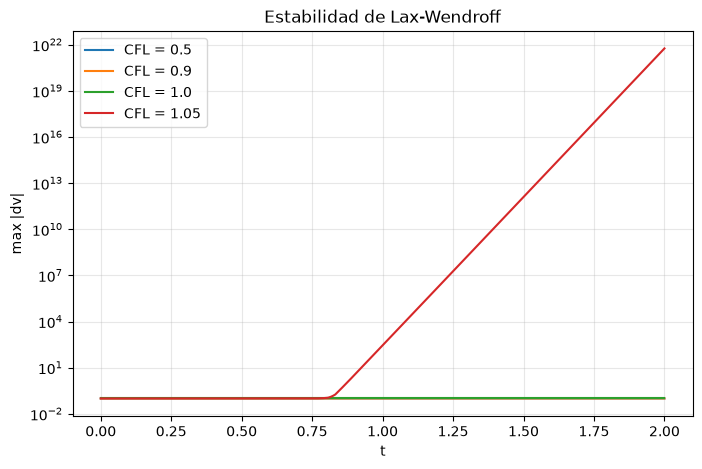

In [10]:
plt.figure(figsize=(8, 5))
for k in range(len(lista_CFL)):
    plt.semilogy(series_t[k], series_max[k], label=f'CFL = {lista_CFL[k]}')
plt.xlabel('t')
plt.ylabel('max |dv|')
plt.title('Estabilidad de Lax-Wendroff')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

## Pregunta 4

In [11]:
t_salida = np.arange(1.0, 11.0, 1.0)
N = 256
CFL = 0.8
dx = L/N
dt = CFL*dx/vA
x = np.linspace(0.5*dx, L - 0.5*dx, N)
seno = np.sin(2*np.pi*x/L)
coseno = np.cos(2*np.pi*x/L)

dv = A*np.sin(2*np.pi*x/L)
dB = A*np.sin(2*np.pi*x/L)
t = 0.0

a_sin = 2.0/N*np.sum(dv*seno)
a_cos = 2.0/N*np.sum(dv*coseno)
amplitudes = [np.sqrt(a_sin**2 + a_cos**2)]
tiempos_amp = [0.0]

for k in range(len(t_salida)):
    n_pasos = int(np.ceil((t_salida[k] - t)/dt - 1e-9))
    dt_paso = (t_salida[k] - t)/n_pasos
    for n in range(n_pasos):
        dv_half = 0.5*(dv + np.roll(dv, -1)) + (dt_paso/(2*dx))*(B0/mu0/rho0)*(np.roll(dB, -1) - dB)
        dB_half = 0.5*(dB + np.roll(dB, -1)) + (dt_paso/(2*dx))*B0*(np.roll(dv, -1) - dv)
        dv = dv + (dt_paso/dx)*(B0/mu0/rho0)*(dB_half - np.roll(dB_half, 1))
        dB = dB + (dt_paso/dx)*B0*(dv_half - np.roll(dv_half, 1))
    t = t_salida[k]
    a_sin = 2.0/N*np.sum(dv*seno)
    a_cos = 2.0/N*np.sum(dv*coseno)
    amplitudes.append(np.sqrt(a_sin**2 + a_cos**2))
    tiempos_amp.append(t)

print('t       amplitud      pérdida (%)')
for k in range(len(tiempos_amp)):
    perdida = 100*(A - amplitudes[k])/A
    print(f'{tiempos_amp[k]:5.1f}   {amplitudes[k]:.8f}   {perdida:.5f}')

t       amplitud      pérdida (%)
  0.0   0.10000000   0.00000
  1.0   0.09999967   0.00033
  2.0   0.09999933   0.00067
  3.0   0.09999900   0.00100
  4.0   0.09999866   0.00134
  5.0   0.09999833   0.00167
  6.0   0.09999799   0.00201
  7.0   0.09999766   0.00234
  8.0   0.09999732   0.00268
  9.0   0.09999699   0.00301
 10.0   0.09999666   0.00334


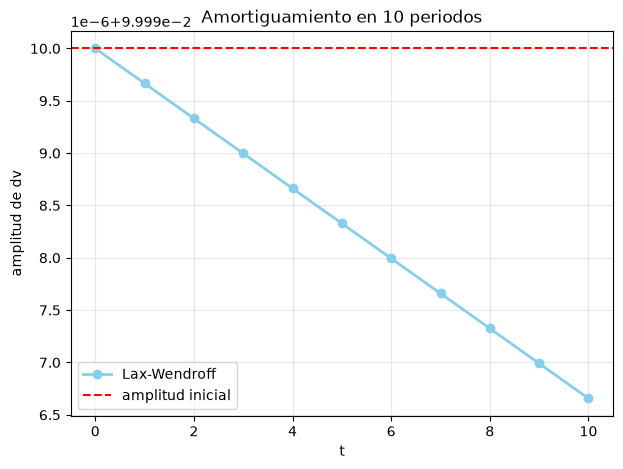

In [12]:
plt.figure(figsize=(7, 5))
plt.plot(tiempos_amp, amplitudes, 'o-', color='skyblue', lw=2, label='Lax-Wendroff')
plt.axhline(A, color='red', ls='--', label='amplitud inicial')
plt.xlabel('t')
plt.ylabel('amplitud de dv')
plt.title('Amortiguamiento en 10 periodos')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Pregunta 5: comparación con PLUTO

In [13]:
import pyPLUTO as pp

N = 256
dx = L/N
x = np.linspace(0.5*dx, L - 0.5*dx, N)

salidas_pluto = [1, 10]
t_pluto = []
By_pluto = []
for n_out in salidas_pluto:
    D = pp.Load(nout=n_out, path='./', text=False)
    t_pluto.append(float(np.squeeze(D.ntime)))
    By_pluto.append(np.asarray(D.Bx2))
x_pluto = np.asarray(D.x1)

print('tiempos de PLUTO:', t_pluto)
print('diferencia entre mallas:', np.max(np.abs(x_pluto - x)))

PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
tiempos de PLUTO: [0.4979265, 5.0]
diferencia entre mallas: 0.0


In [14]:
CFL = 0.8
dt = CFL*dx/vA

dv = A*np.sin(2*np.pi*x/L)
dB = A*np.sin(2*np.pi*x/L)
t = 0.0
By_python = []

for k in range(len(t_pluto)):
    n_pasos = int(np.ceil((t_pluto[k] - t)/dt - 1e-9))
    dt_paso = (t_pluto[k] - t)/n_pasos
    for n in range(n_pasos):
        dv_half = 0.5*(dv + np.roll(dv, -1)) + (dt_paso/(2*dx))*(B0/mu0/rho0)*(np.roll(dB, -1) - dB)
        dB_half = 0.5*(dB + np.roll(dB, -1)) + (dt_paso/(2*dx))*B0*(np.roll(dv, -1) - dv)
        dv = dv + (dt_paso/dx)*(B0/mu0/rho0)*(dB_half - np.roll(dB_half, 1))
        dB = dB + (dt_paso/dx)*B0*(dv_half - np.roll(dv_half, 1))
    t = t_pluto[k]
    By_python.append(dB.copy())

print('t         L1 PLUTO     L1 Python    max|By| PLUTO   max|By| Python')
for k in range(len(t_pluto)):
    By_exacta = A*np.sin(2*np.pi*(x + vA*t_pluto[k])/L)
    e_pluto = np.mean(np.abs(By_pluto[k] - By_exacta))
    e_python = np.mean(np.abs(By_python[k] - By_exacta))
    print(f'{t_pluto[k]:.4f}    {e_pluto:.3e}    {e_python:.3e}    {np.max(np.abs(By_pluto[k])):.5f}         {np.max(np.abs(By_python[k])):.5f}')

t         L1 PLUTO     L1 Python    max|By| PLUTO   max|By| Python
0.4979    3.990e-05    7.305e-06    0.09973         0.10000
5.0000    3.629e-04    7.244e-05    0.09859         0.09999


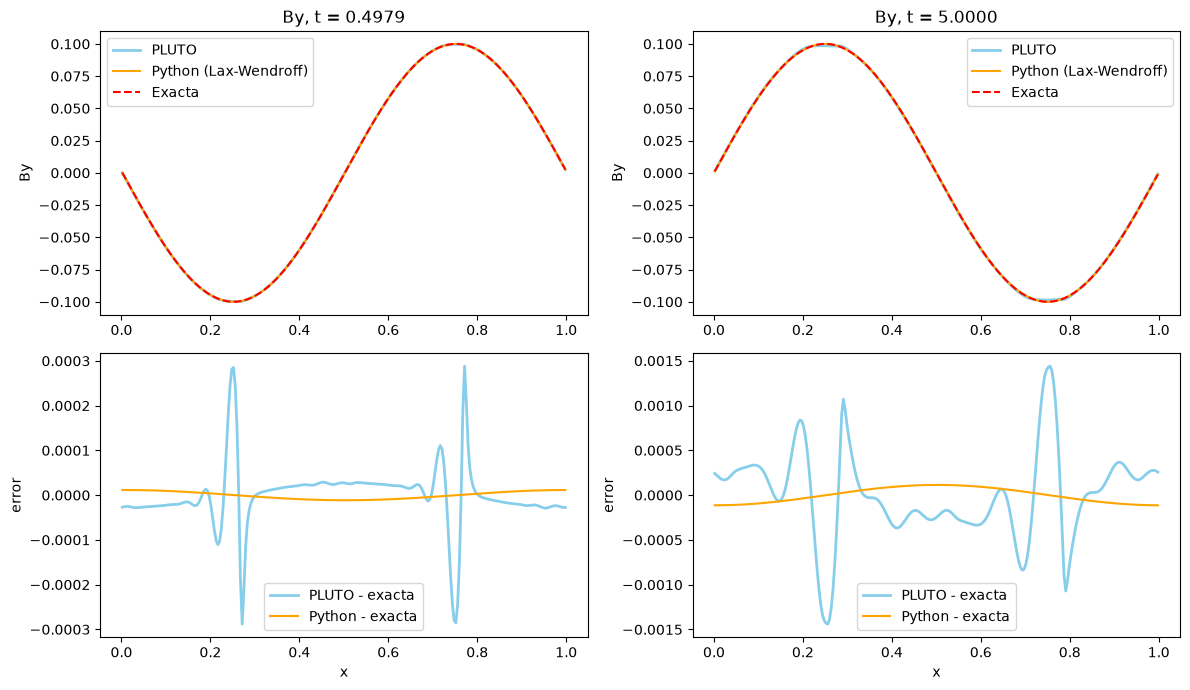

In [15]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
for k in range(len(t_pluto)):
    By_exacta = A*np.sin(2*np.pi*(x + vA*t_pluto[k])/L)
    ejes[0, k].plot(x, By_pluto[k], color='skyblue', lw=2, label='PLUTO')
    ejes[0, k].plot(x, By_python[k], color='orange', lw=1.5, label='Python (Lax-Wendroff)')
    ejes[0, k].plot(x, By_exacta, '--', color='red', label='Exacta')
    ejes[0, k].set_title(f'By, t = {t_pluto[k]:.4f}')
    ejes[0, k].set_ylabel('By')
    ejes[0, k].legend()
    ejes[1, k].plot(x, By_pluto[k] - By_exacta, color='skyblue', lw=2, label='PLUTO - exacta')
    ejes[1, k].plot(x, By_python[k] - By_exacta, color='orange', lw=1.5, label='Python - exacta')
    ejes[1, k].set_xlabel('x')
    ejes[1, k].set_ylabel('error')
    ejes[1, k].legend()
plt.tight_layout()
plt.show()

## Respuestas

**1.** La onda viaja hacia −x con velocidad 0.999964, que coincide con vA = 1 (error 3.6e-5).

**2.** El error L1 baja como N⁻²: el orden de convergencia es p ≈ 2.0 (1.998), segundo orden, como se espera de Lax-Wendroff.

**3.** Es estable para CFL ≤ 1 (0.5, 0.9 y 1.0) e inestable con CFL = 1.05. Upwind tiene el mismo límite, pero es de primer orden y difunde más.

**4.** En t = 10 la amplitud pasa de 0.1 a 0.09999666, una pérdida de solo 0.0033 %. RK2 con diferencias centradas no amortigua la amplitud.

**5.** Las dos soluciones coinciden. El error L1 de Python (7.3e-6 y 7.2e-5) es unas 5 veces menor que el de PLUTO (4.0e-5 y 3.6e-4). PLUTO pierde amplitud y Lax-Wendroff no.